# 07 · 从我们写的 Transformer，看懂 Qwen

这一课先看完整结构，再沿箭头展开内部计算，最后用代码演示。无需先猜参数，也无需先运行代码才能看图。

我们对照的是 **06 的书籍实验配置**与 **Qwen3-0.6B 的固定版本**。先从下往上看两张网络图：熟悉的部分在哪里，变化的部分在哪里？

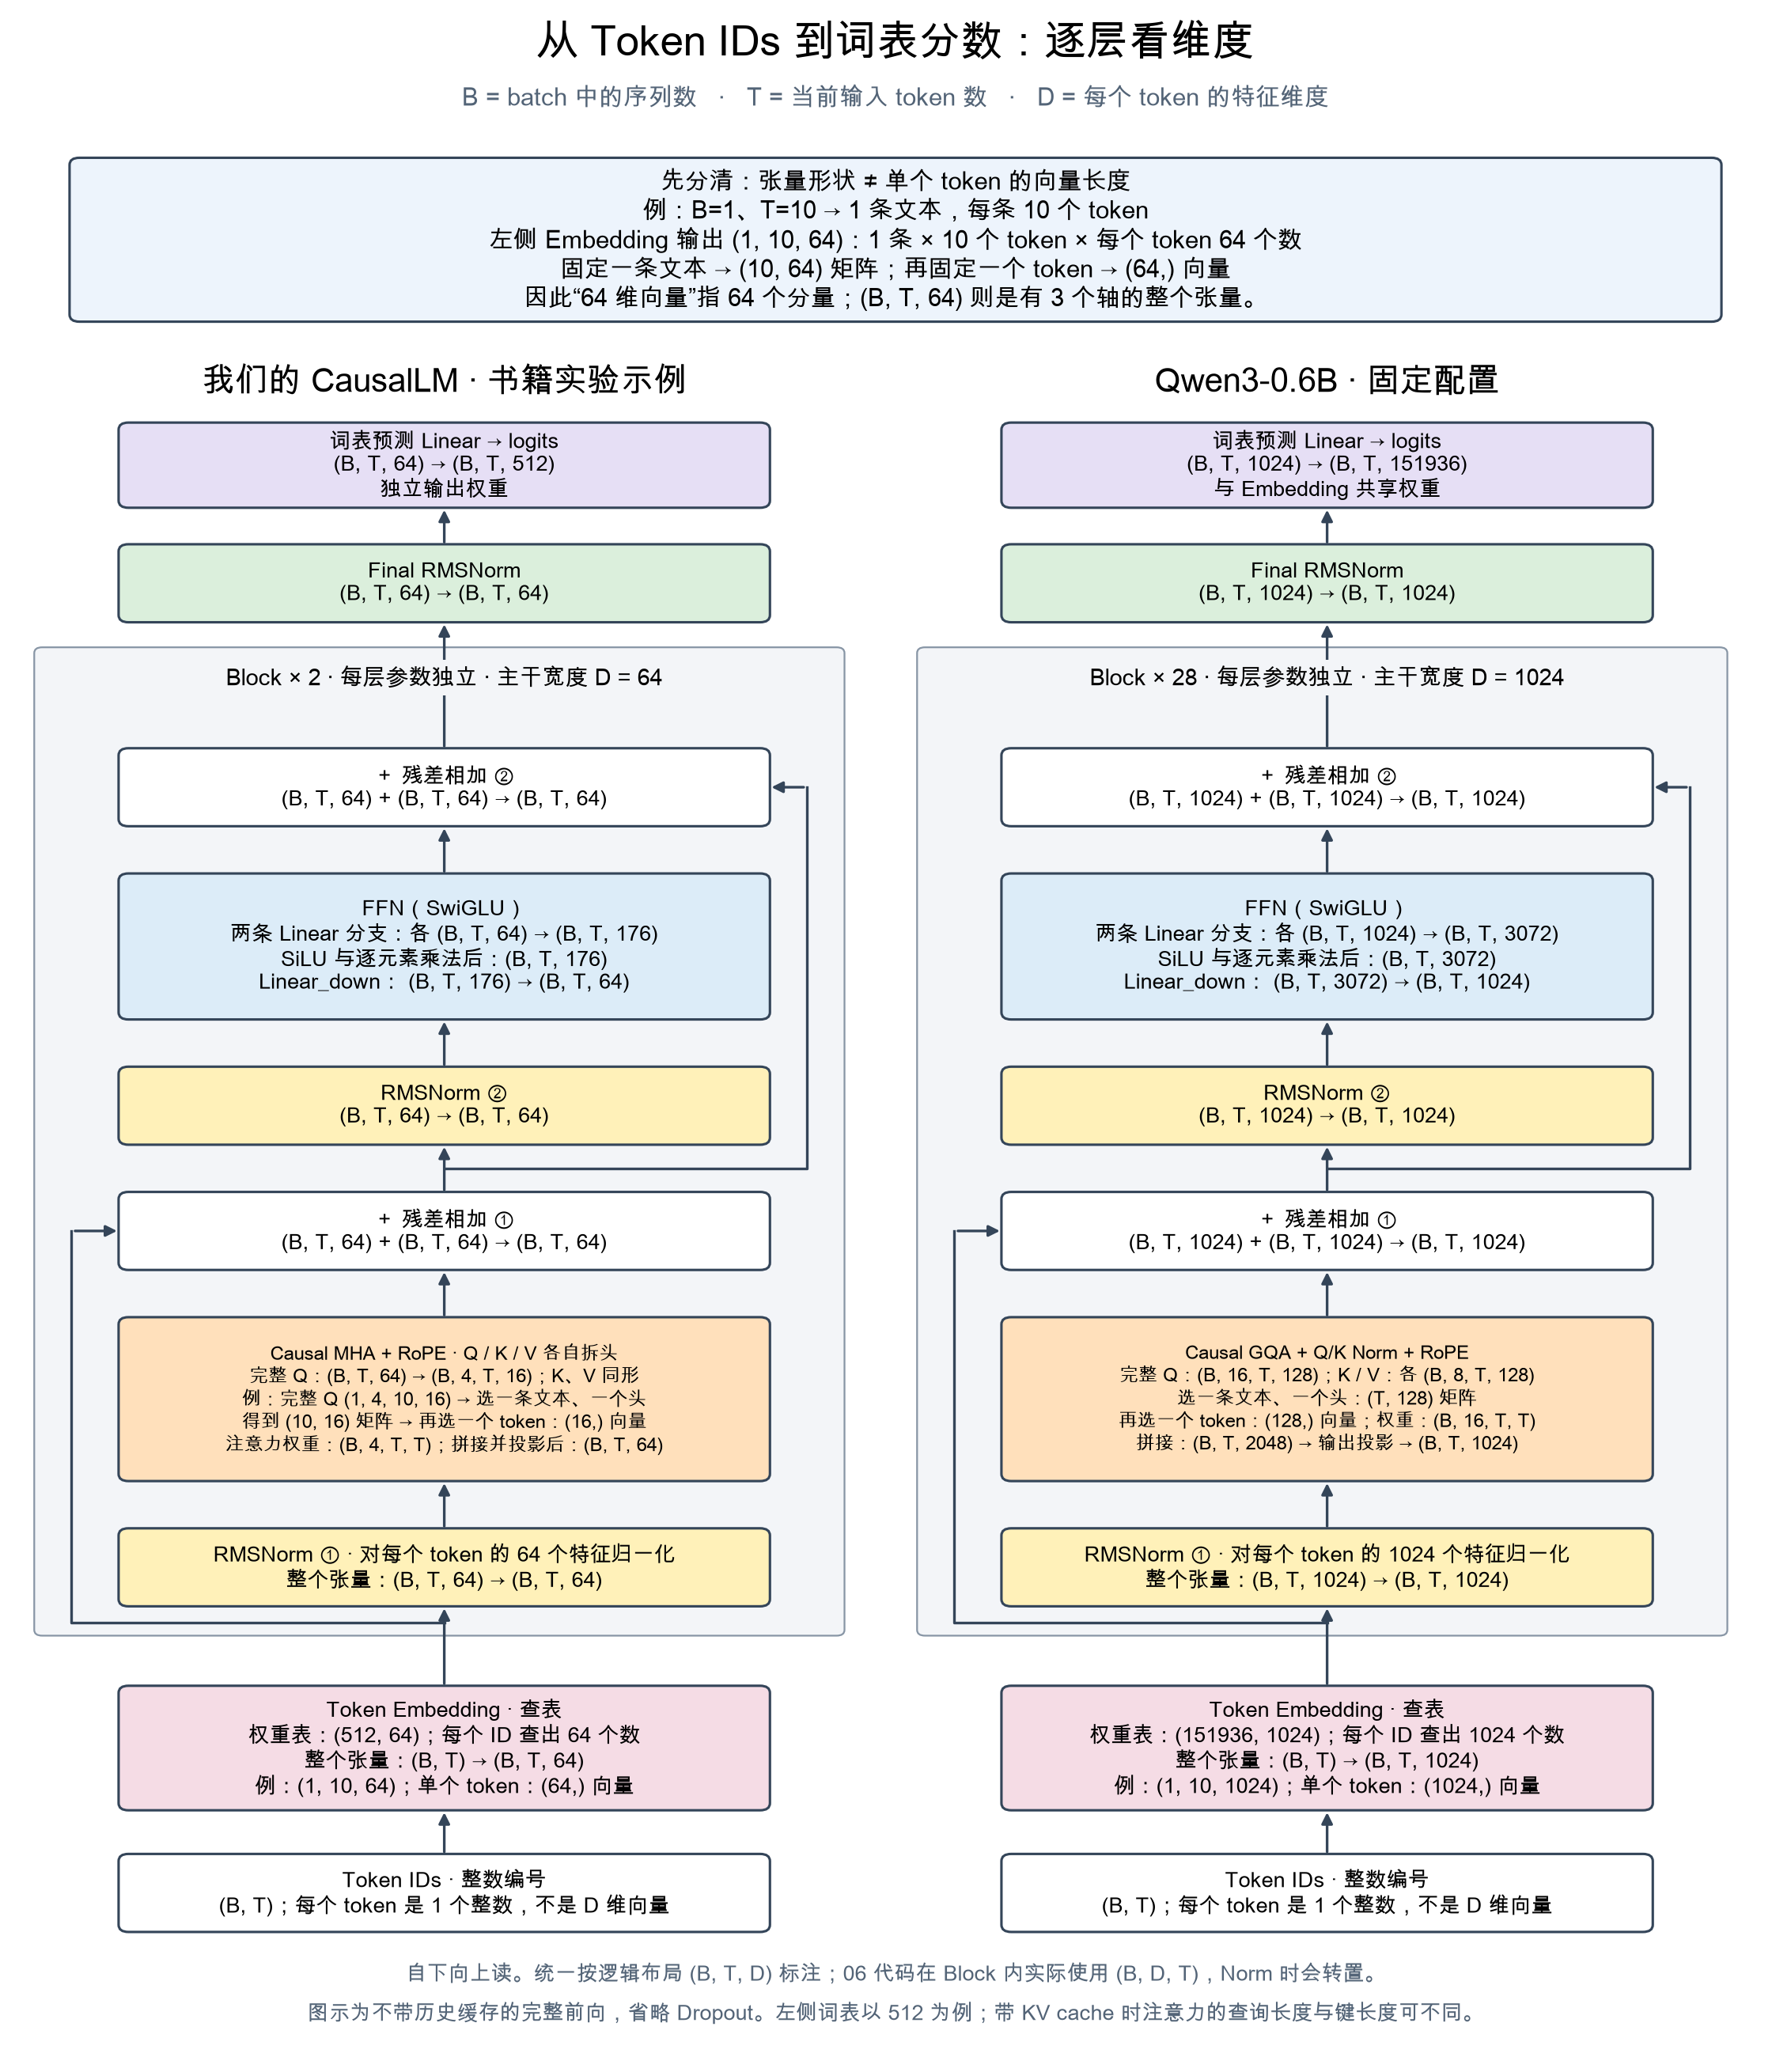

## 1 · 先沿主干走一遍

把一句话分词得到 Token IDs，Embedding 把每个 ID 变成向量。向量进入一层层 Block，最后经过 Final RMSNorm 和词表预测层，得到下一个 token 的分数（logits）。生成时再由分数计算概率、采样，接回输入继续生成。

**左右两边的主体流程相同，都是 Decoder-only。** 没有 Encoder 输出接入，所以也没有 Cross-Attention。

灰框内的一层可以写成：

```python
h = x + attention(rms_norm_1(x))
y = h + swiglu(rms_norm_2(h))
```

注意旁路箭头：残差保留的是 Norm 之前的输入。这里是我们后来实现的 **Pre-Norm**，不同于最初学习原始 Transformer 时的 Add & Norm 顺序。灰框重复多次，每一层有自己的参数。

RoPE 在 Attention 内部处理 Q/K，所以这里没有在 Embedding 后面画“加位置向量”。图中省略了训练时的 Dropout；左图尺寸是书籍实验的设置，不是模型类唯一支持的尺寸。

## 2 · 放大橙色方块：真正变化发生在哪里？

Qwen 仍然是先算 Q、K、V，再做缩放点积注意力。先看三条分支，之后再解释数字。

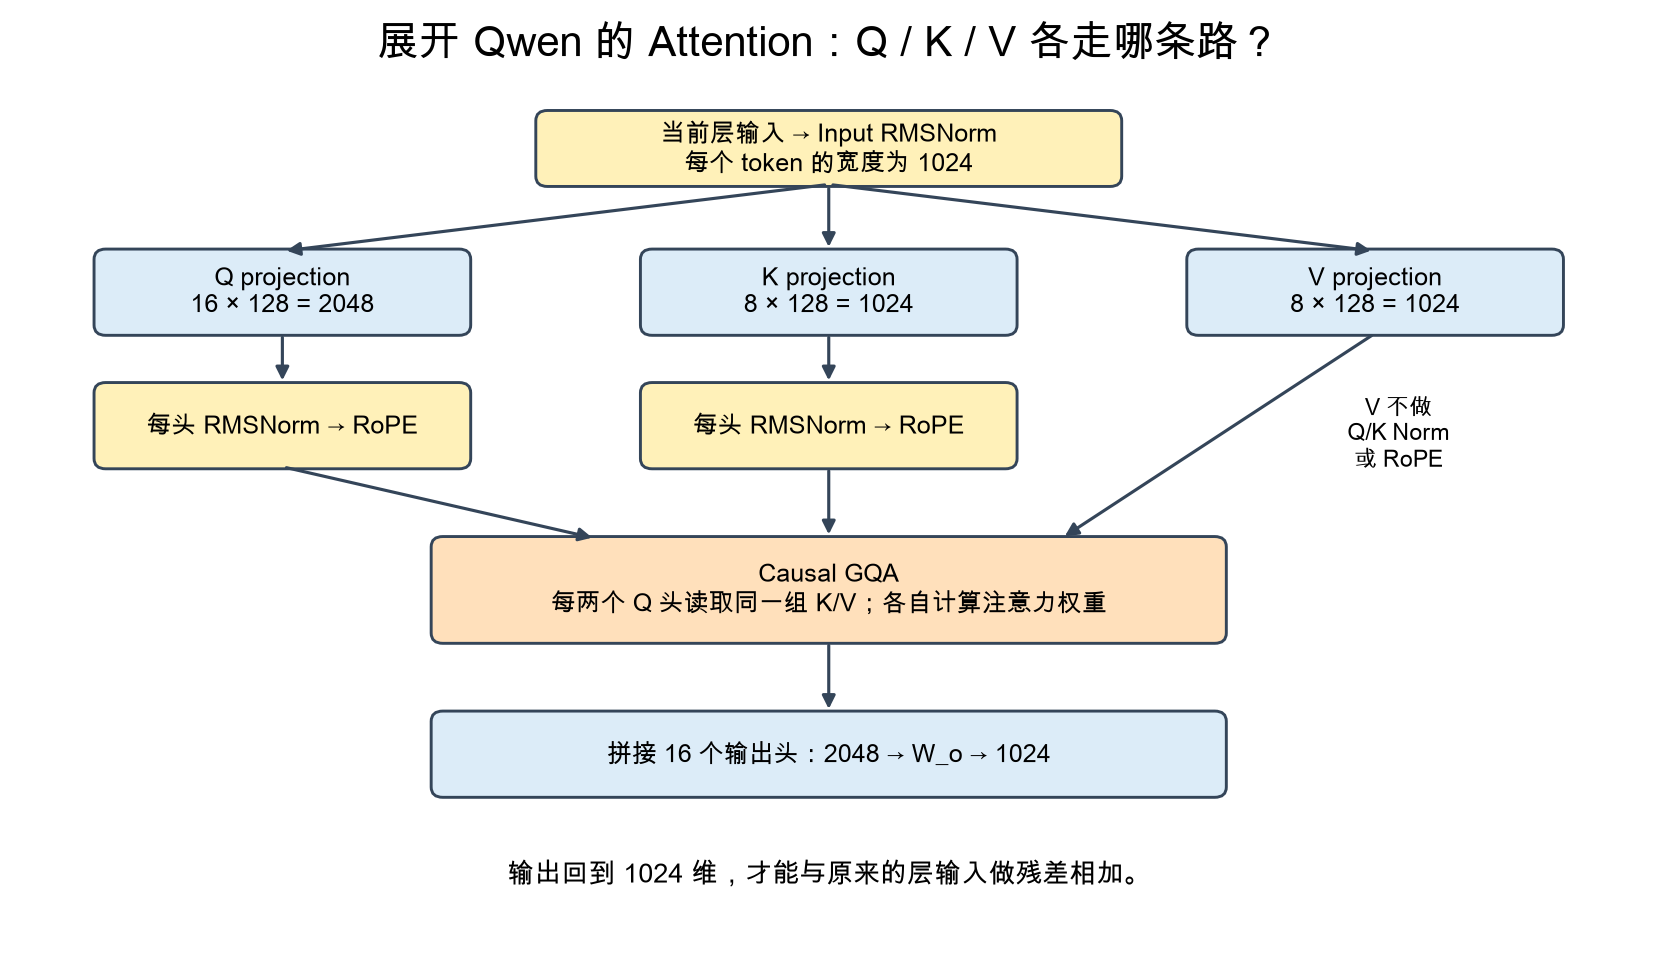

### 展开到每一个 token：Q/K/V 的维度

下图以一条文本、4 个 token 为例。下标是 token 位置，头编号单独标注；图中推导采用列向量，batch 张量采用 `(B,T,D)`，两者是不同的排列约定。

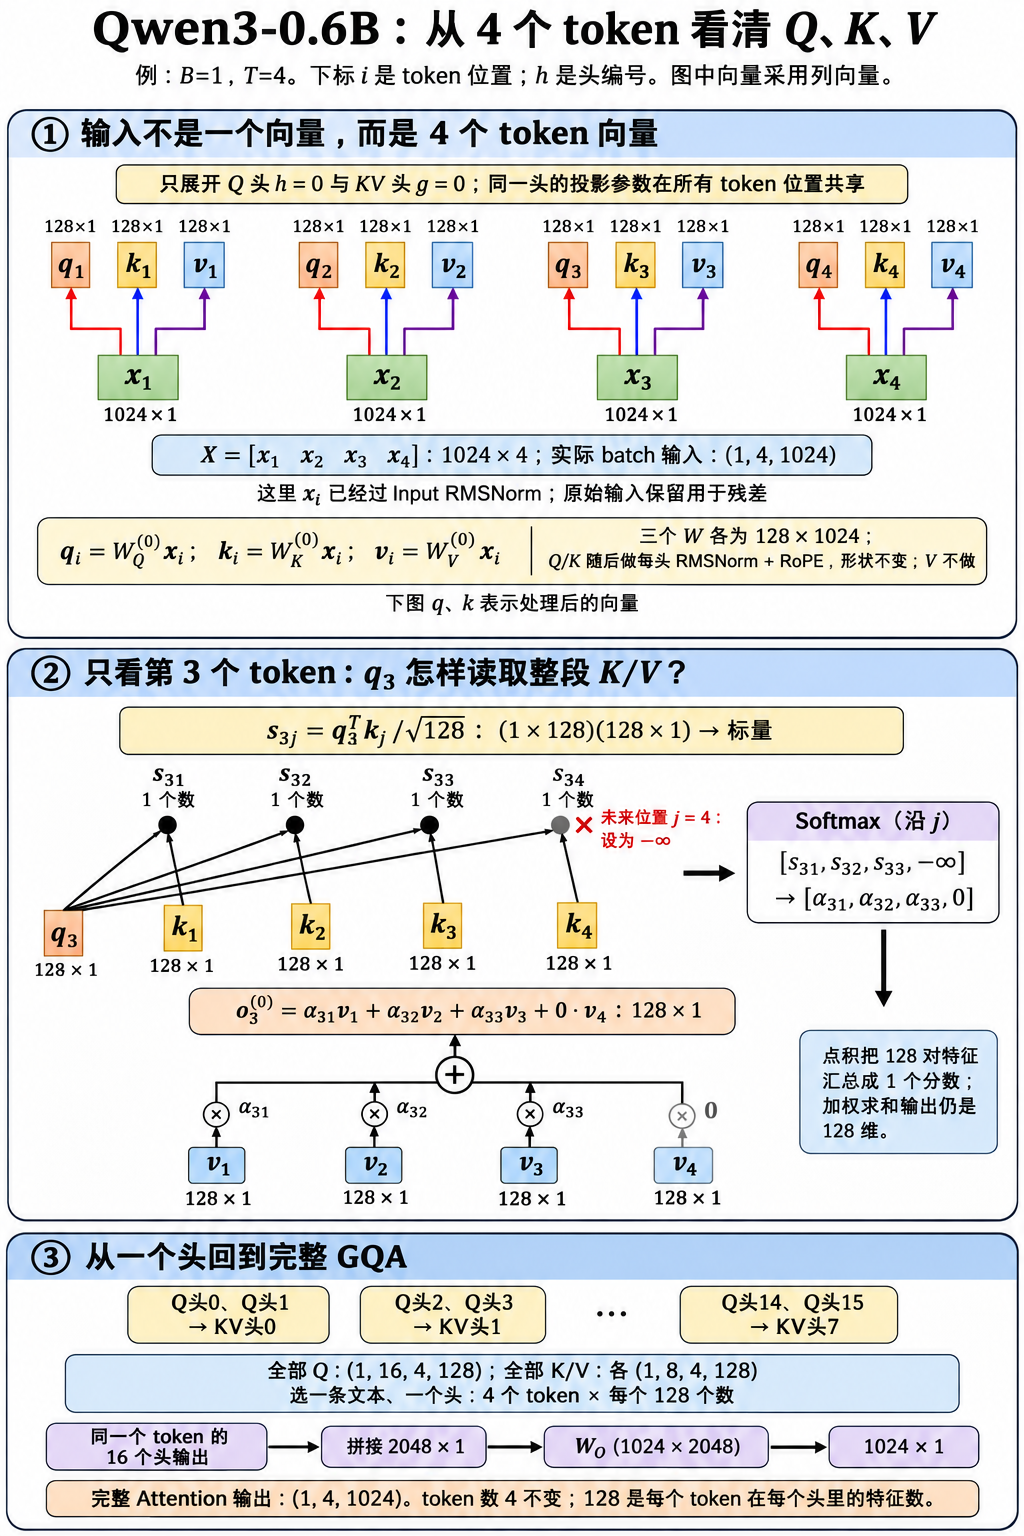

按箭头读这张图：

1. 当前层输入先做 **Input RMSNorm**，然后通过三个不同的线性层得到 Q、K、V。
2. Q、K 拆头后各做一次 **每头 RMSNorm**，再做 **RoPE**。这是比我们的实现多出来的 Q/K Norm；V 不经过这两步。
3. **Causal GQA** 决定每个 Q 头读取哪组 K/V。计算仍是 `softmax(Q @ K.T / sqrt(head_dim) + mask) @ V`，未来位置在 softmax 前被遮挡。
4. 各头输出拼接，再通过输出投影回到输入宽度，接上残差。

这里两类 Norm 的作用范围不同：Input RMSNorm 对每个 token 的 1024 个特征归一化；Q/K Norm 对每个头的 128 个特征归一化。它们都不改变维度。

## 3 · GQA：多个查询，读取同一份 K/V

我们原来的 MHA 中，每个 Q 头对应自己的一组 K/V。GQA 把若干 Q 头分为一组，让它们读取同一组 K/V。先把头数缩小来看：

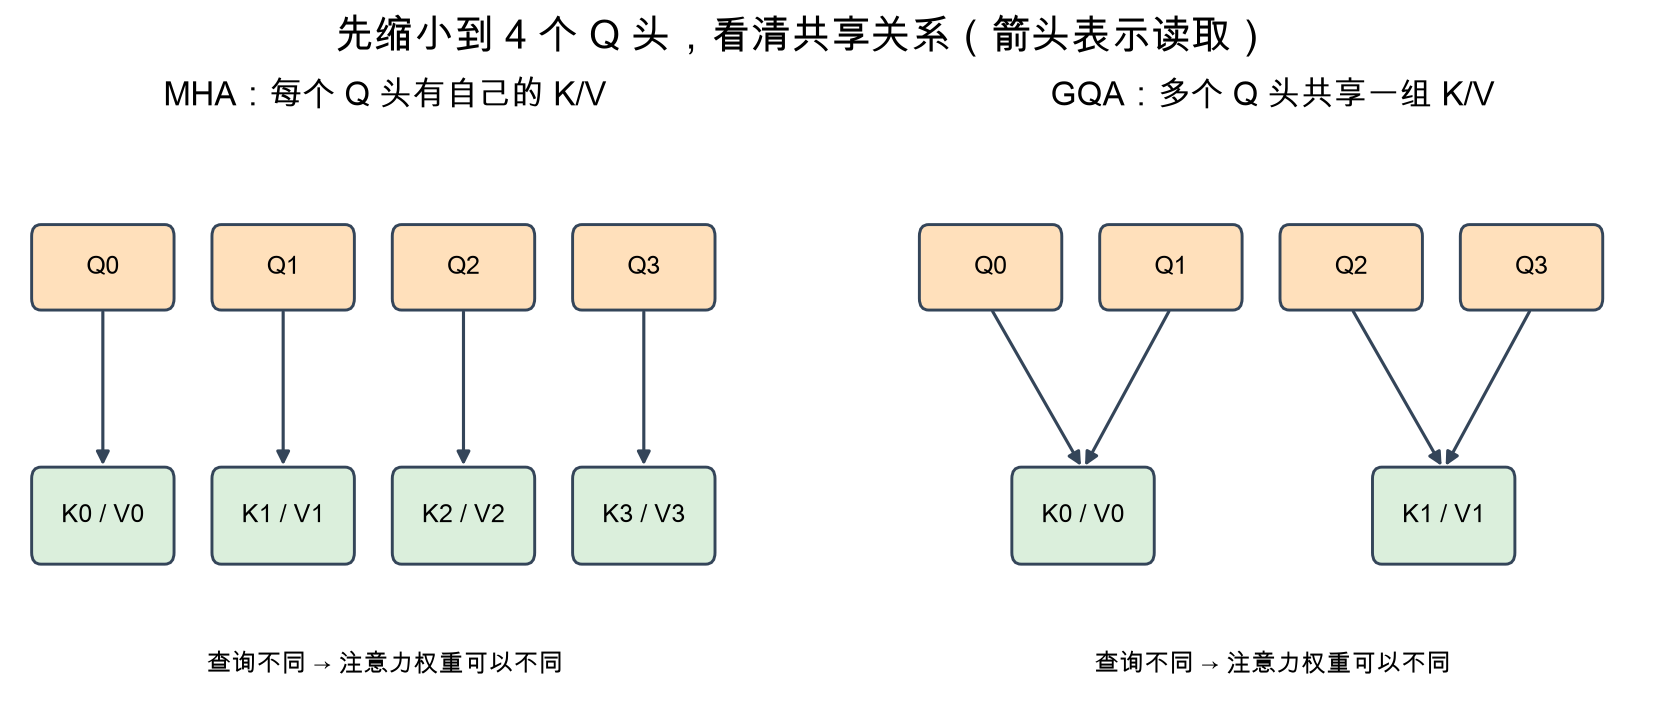

右图 Q0、Q1 的查询向量仍各自计算；共享的是 K0/V0。它们可以关注不同位置，因此输出可以不同。

为什么这样设计？生成时每一层都要保存历史 K/V，供后续 token 读取。减少 KV 头数，就能减少缓存存储量和读取量，同时保留多个 Q 头。它对模型表达能力也有影响，需要通过训练和评估验证效果；不是随意删掉已训练 MHA 的一半头。

Qwen 这份配置将这个关系放大为 **16 个 Q 头，8 组 K/V，每两个 Q 头共享一组 K/V**。

### 直接看一次计算：共享 K/V 为什么不等于相同输出？

下面是人为选定的小矩阵，用来演示计算，不是 Qwen 的权重。我们只看最后一个位置的两个 Q 头；三个历史位置都允许读取，因此不额外遮挡。

In [1]:
import math
import torch

torch.set_printoptions(precision=3, sci_mode=False)
# 两个 Q 头在同一个位置的查询
queries = torch.tensor([[1., 0.], [0., 1.]])
# 它们共享三个可见位置的 K/V
keys = torch.tensor([[2., 0.], [0., 2.], [1., 1.]])
values = torch.tensor([[10., 0.], [0., 10.], [5., 5.]])
weights = torch.softmax(queries @ keys.T / math.sqrt(2), dim=-1)
outputs = weights @ values
for i in range(2):
    print(f'Q{i} = {queries[i].tolist()}')
    print('  对三个位置的注意力权重:', weights[i])
    print('  汇总同一份 V 得到的输出:', outputs[i])

Q0 = [1.0, 0.0]
  对三个位置的注意力权重: tensor([0.576, 0.140, 0.284])
  汇总同一份 V 得到的输出: tensor([7.180, 2.820])
Q1 = [0.0, 1.0]
  对三个位置的注意力权重: tensor([0.140, 0.576, 0.284])
  汇总同一份 V 得到的输出: tensor([2.820, 7.180])


你会看到：Q0 更关注第一个位置，Q1 更关注第二个位置，输出分别约为 `[7.18, 2.82]` 和 `[2.82, 7.18]`。

区别来自 Q；K、V 完全相同。这样就能把图里的“共享”与实际矩阵计算对应起来。

## 4 · 现在再读数字：1024 为什么能变成 2048？

`hidden_size=1024` 表示主干中每个 token 的宽度。它不要求 Attention 内部一直保持这个宽度。

| 经过哪里 | 每个 token 的表示 |
|---|---|
| 进入 Attention | 1024 维 |
| Q 投影并拆头 | 16 个头，每头 128 维，总宽度 2048 |
| K/V 投影并拆头 | 各 8 个头，每头 128 维，总宽度 1024 |
| 每个 Q 头读取 V 后 | 仍有 16 个输出头，每头 128 维 |
| 拼接，再经过输出投影 | 2048 → 1024 |
| 与原输入残差相加 | 1024 + 1024 |

所以 `head_dim` 不能在这里直接用 `hidden_size / num_attention_heads` 推算。真正决定能不能残差相加的是**子层最终输出的维度**。

下面只读取本地保存的官方配置，让数字和图一一对应。配置文件描述网络尺寸；训练好的权重是另一些文件。知道网络长什么样不需要先下载它学到的全部参数。

In [ ]:
from pathlib import Path
import sys

root = Path.cwd()
lesson_dir = root if (root / 'inspect_architecture.py').exists() else root / '07-modern-llm'
sys.path.insert(0, str(lesson_dir.resolve()))
from inspect_architecture import load_config, describe

config = load_config()
for name in ('hidden_size', 'num_hidden_layers', 'num_attention_heads',
             'num_key_value_heads', 'head_dim'):
    print(f'{name} = {config[name]}')

## 5 · 回到完整结构：还有哪些差异？

**SwiGLU 已经学过，结构继续保留。** 这份 Qwen 的中间宽度是 3072：两路投影分别得到 gate 和 up，计算 `SiLU(gate) * up`，再投影回 1024。它不是把原向量后面补零。

**输出层和 Embedding 共享同一个参数矩阵。** 设 `E` 的形状为 `(词表大小, 1024)`：输入时用 `E[token_id]` 查向量；输出时用 `hidden @ E.T` 得到每个词的分数。它们仍处在网络的不同位置，只是使用同一份参数。我们 06 的模型用的是两份独立参数。

**模型更深更宽，但训练同样关键。** 仅根据配置随机初始化出这张网络，不会获得 Qwen 的语言能力。训练数据、优化过程、预训练与后训练，决定了这些权重最终学到什么。

| 对照项 | 我们的书籍实验 | 此版本 Qwen3-0.6B |
|---|---|---|
| Block 数量 / 主干宽度 | 2 / 64 | 28 / 1024 |
| Attention | MHA，4 Q / 4 KV | GQA，16 Q / 8 KV |
| Q/K Norm | 无 | 有 |
| FFN | SwiGLU，中间宽度 176 | SwiGLU，中间宽度 3072 |
| Embedding / 输出层 | 独立参数 | 共享参数 |
| RoPE 基数 theta | 10000 | 1000000 |

RoPE 实现还采用不同的特征配对约定：我们按相邻维度，所链接的 Qwen 实现按前后半区配对；因此不能直接互换投影权重。

## 6 · 把图对应到小型代码

看懂关系后，可以运行已有的 `TinyGQA`。它只实现投影、分头、因果注意力和输出投影，便于单独观察 GQA；没有声称复现完整 Qwen。

输入和输出宽度相同；中间 Q 头数比 KV 头数多。演示代码临时复制 K/V 供矩阵计算，缓存本身应保存复制之前的 K/V。

In [ ]:
from gqa_demo import run_demo
model, x, output, details = run_demo()

## 附录 · GQA 节省的缓存具体有多少？

看完结构再看这个估算即可。标准未量化 KV cache 的存储量是：

`2（K 与 V）× batch × token 数 × 层数 × KV 头数 × 每头维度 × 每元素字节数`

固定其余条件，从 16 个 KV 头变成 8 个，缓存数据量减半。这不代表模型总内存减半，也不代表速度翻倍。

In [ ]:
report = describe(config, batch=1, tokens=1024, bytes_per_element=2)
s = report['storage']
print(f"Qwen 配置的 KV cache：{s['kv_cache_mib']:.0f} MiB")
print(f"假设改成 16 个 KV 头：{s['hypothetical_mha_cache_mib']:.0f} MiB")
print(f"仅权重数据：{s['weights_gib']:.2f} GiB（不含激活、缓存或训练状态）")

## 补充实验 · Qwen 的高频、低频到底在哪里？

使用本章固定的真实配置：主干宽度 1024，16 个 Q 头、8 组 KV 头，每头 128 维，RoPE 基数 1,000,000。每头内部有 64 对特征，频率 `theta_i = 1000000 ** (-2*i/128)`。

采用 Qwen 的前后半区配对：第 i 对为 `(i, i+64)`，编号从 0 开始。这里的编号是投影后每个头的特征编号，不是原始 Embedding 的某一维，也不是 token 位置。

**实验边界：真实模型配置 + 人工构造的 Q/K，不加载预训练权重，不进行训练。** 要测真实 Qwen 学到了什么，须另外采集真实文本的 Q/K 与注意力。这里分离内容、模长与位置因素，验证频率本身如何影响计算。

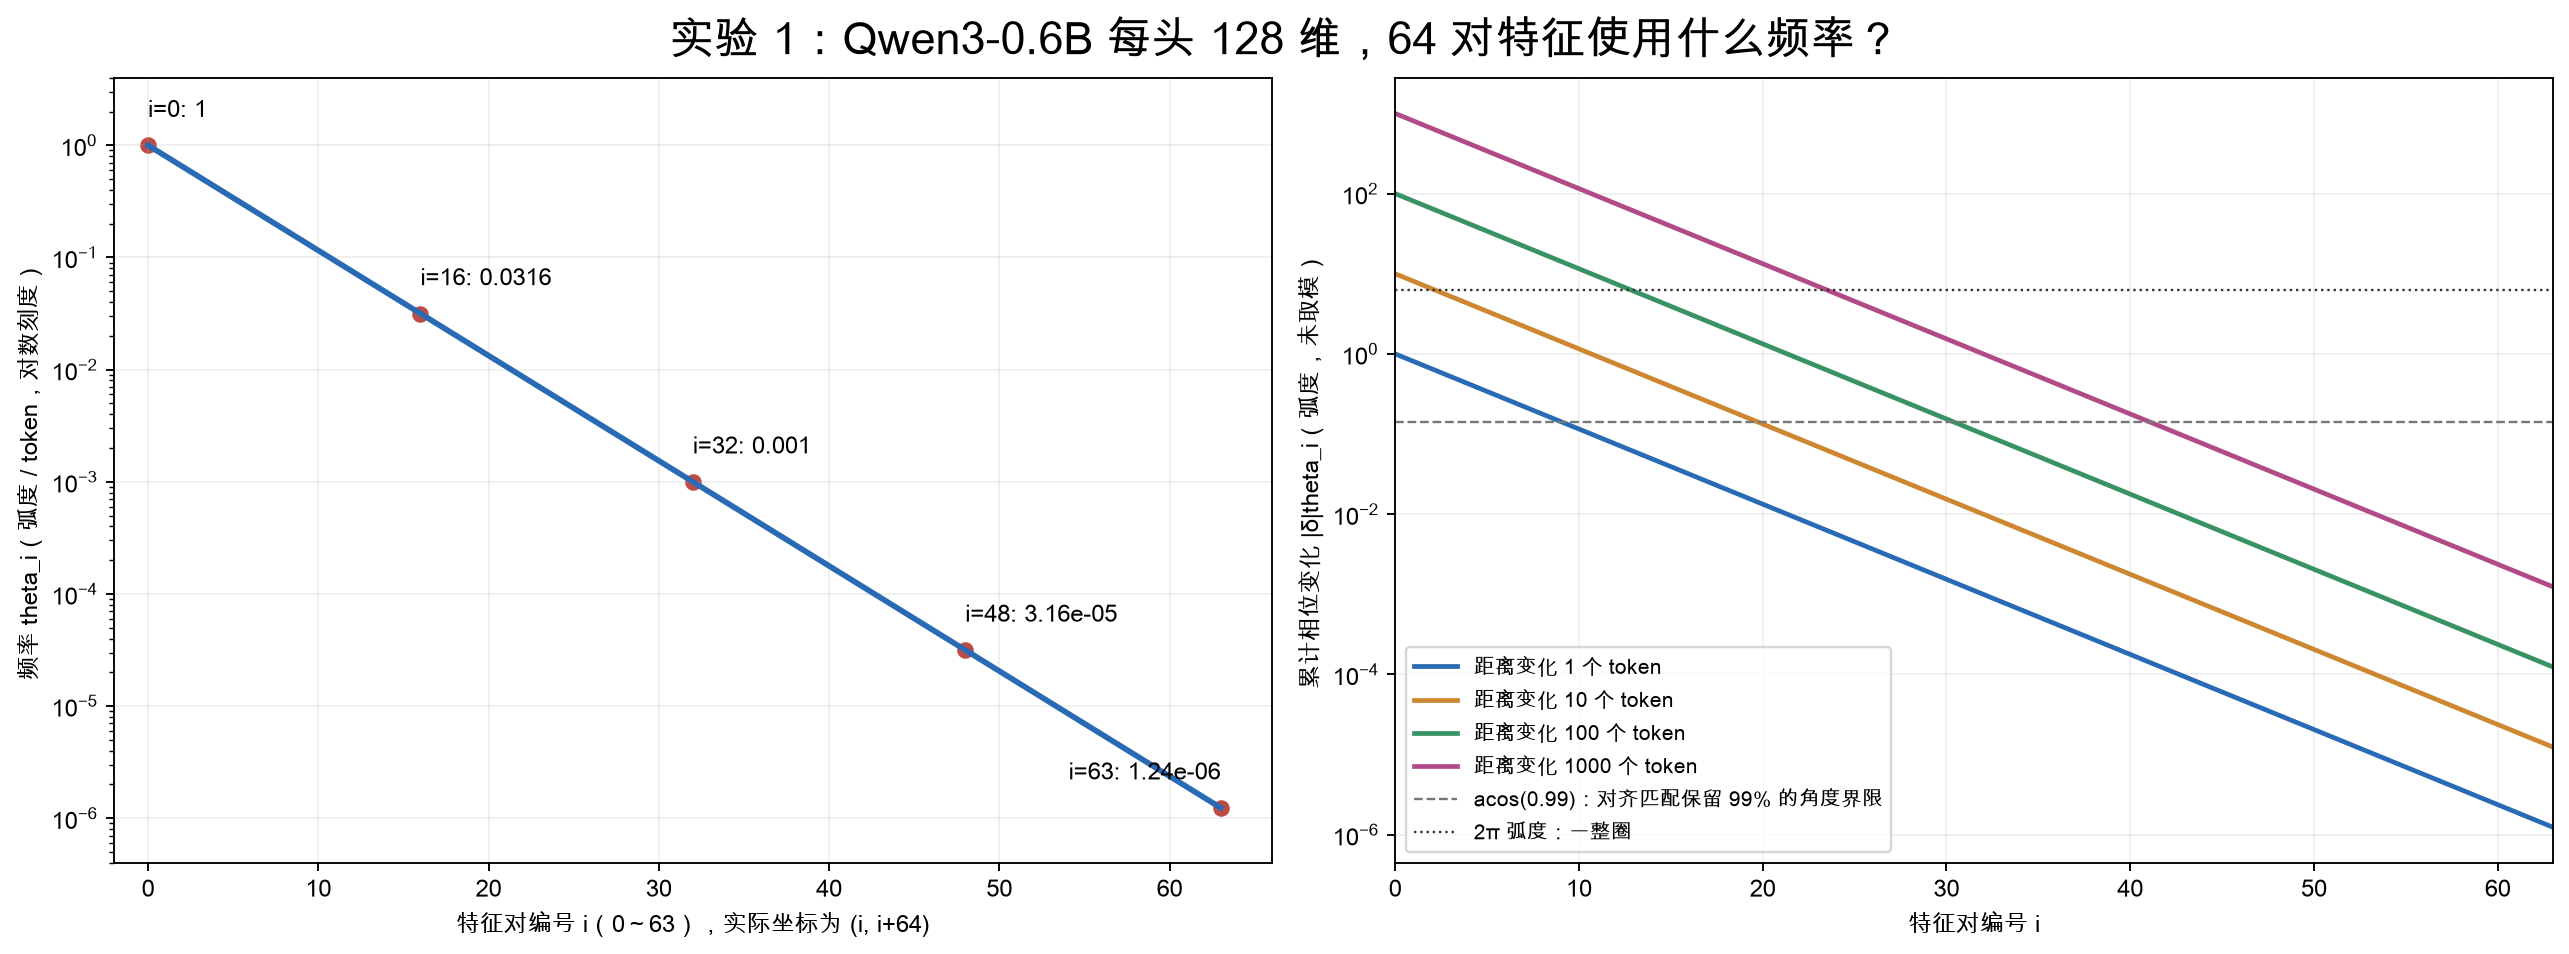

### 固定 Q=K，仅改变位置

每次使用完整 128 维向量，只把能量放在指定的一对特征中，其余为 0。所有向量模长均为 `sqrt(128)`。它们代表人为构造的 Q/K Norm 之后、RoPE 之前的表示；并非实际训练权重算出的特征。

图中的分数是旋转后点积除以两向量模长的乘积，等于余弦相似度，不是 softmax 概率。这个对齐例子中，分数恰好为 `cos(距离 * theta_i)`。

| 特征对编号 | 实际坐标 | 每 token 旋转（弧度） | 距离 1 的分数 | 距离 100 的分数 | 距离 1000 的分数 |
|---|---|---:|---:|---:|---:|
| 0 | (0,64) | 1 | 0.540302 | 0.862319 | 0.562379 |
| 16 | (16,80) | 0.0316228 | 0.999500 | -0.999786 | 0.978683 |
| 32 | (32,96) | 0.001 | 0.9999995 | 0.995004 | 0.540302 |
| 48 | (48,112) | 0.0000316228 | 0.9999999995 | 0.999995 | 0.999500 |

高频会振荡，所以“位置敏感”不等于“距离越大分数越低”。低频也不是完全不受位置影响；要结合观察范围。

**用一个明确标准定义宽容：对齐分数为 1，从距离 0 到 L 始终保持至少 0.99。** 要求 `L*theta_i <= acos(0.99)`。真实频率下：

| 观察范围 L | 满足上述标准的特征对编号 |
|---:|---|
| 1 token | 10～63 |
| 10 tokens | 20～63 |
| 100 tokens | 31～63 |
| 1000 tokens | 42～63 |

0.99 是本实验人为选择的可量化标准，不是官方高/低频划分。

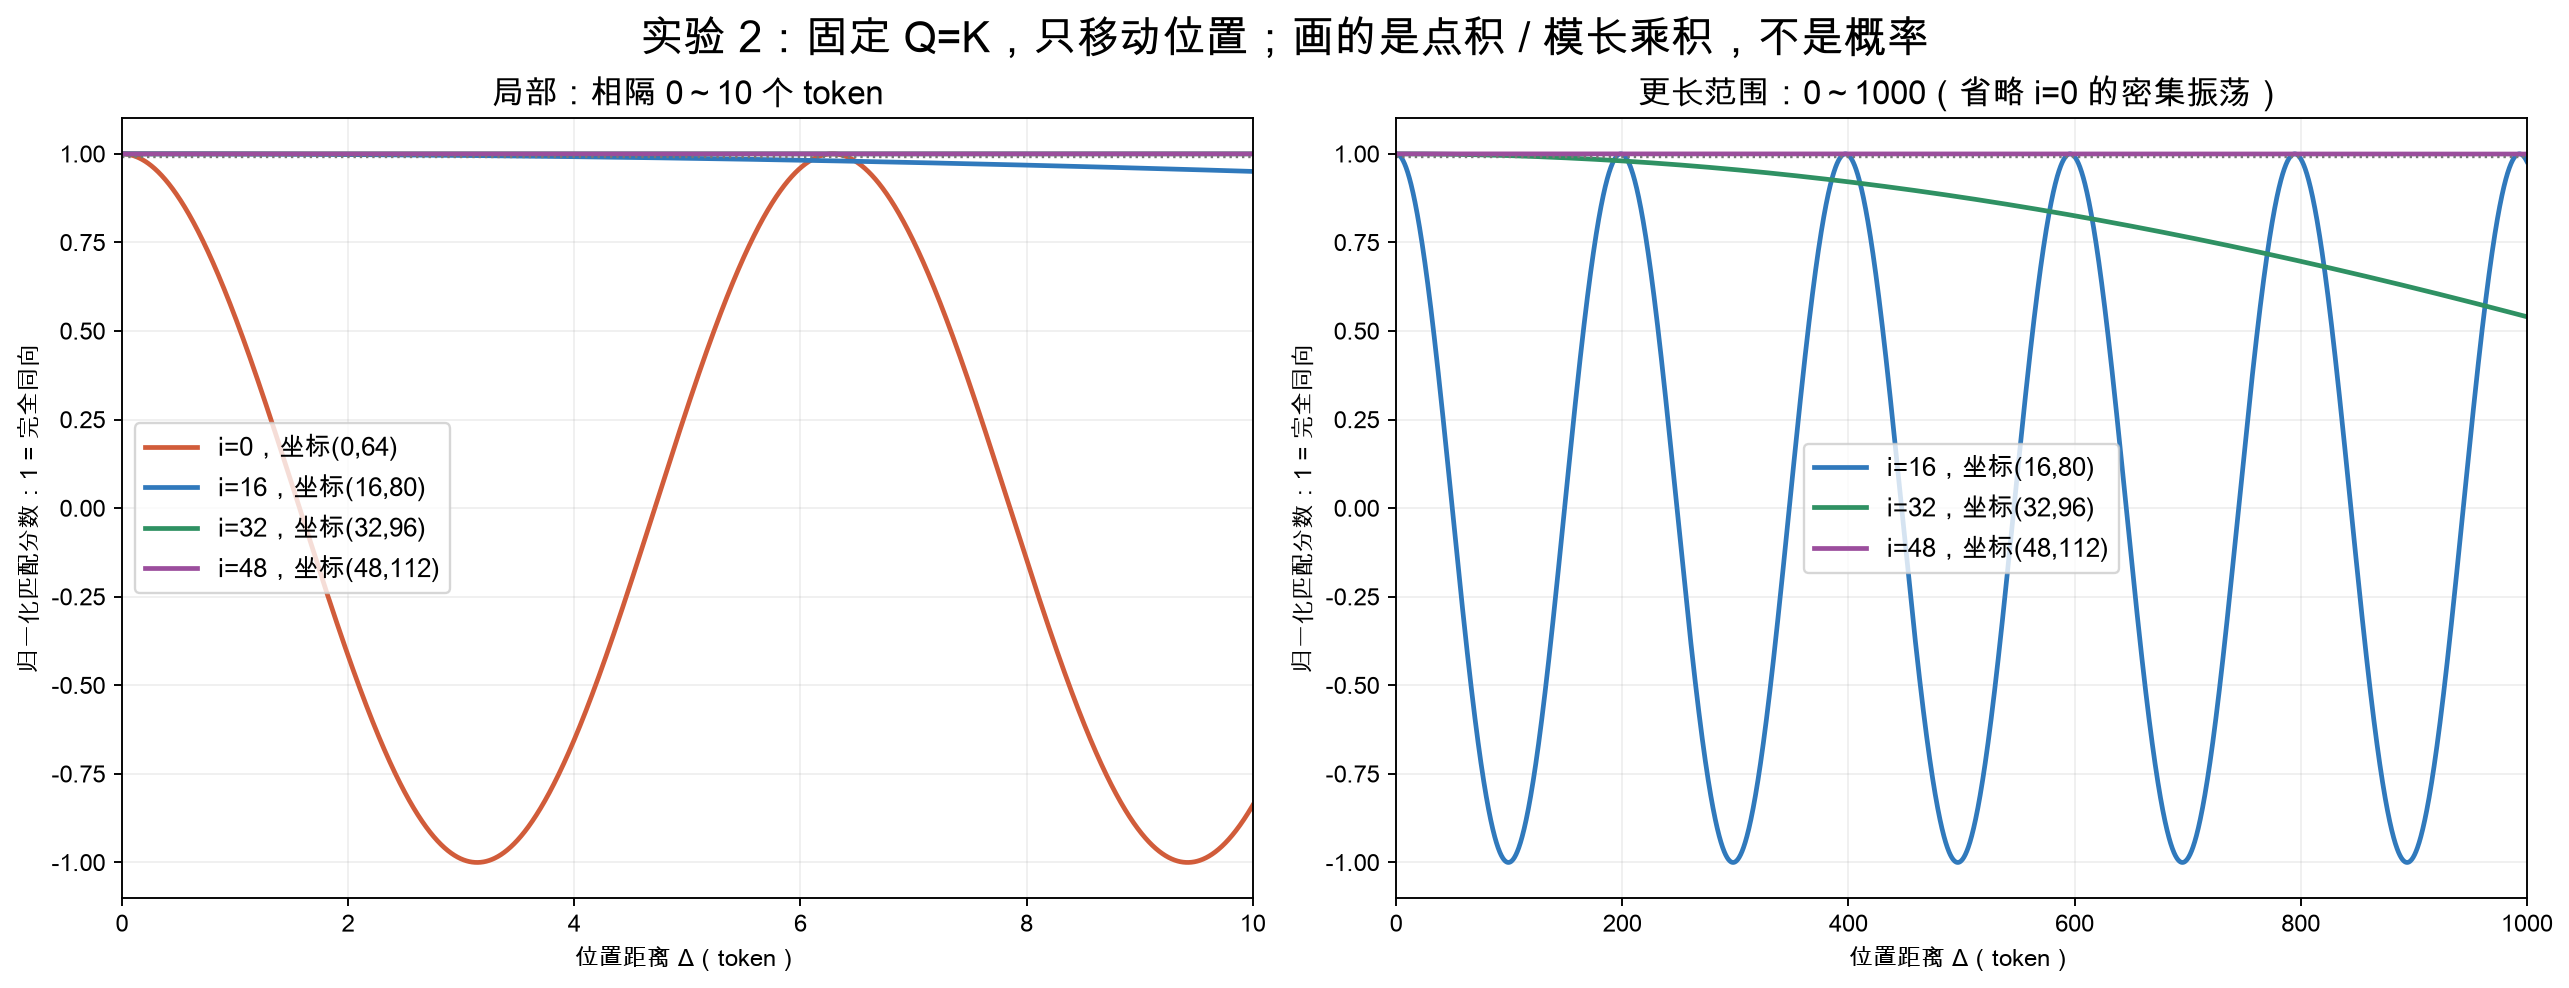

### 人工构造“精确读取前一个 token”

当前 Q 在位置 256，129 个候选 K 位于 128～256；所有 K 在旋转前的内容完全相同。Q 取 `rotate(K, -1)`，使距离为 1 的 K 与 Q 在旋转后完全对齐。设置同样的模长和缩放，比较：

- 较高频：8 对编号 0～7，即坐标 0～7 与 64～71。
- 较低频：8 对编号 32～39，即坐标 32～39 与 96～103。

这两组人为表示只改变使用的频段，并根据各自频率构造目标对齐。每组内部移动候选 K 时，内容保持不变。

| 候选距 Q 多远 | 高频归一化分数 | 低频归一化分数 |
|---:|---:|---:|
| 1（目标） | 1.000000 | 1.000000 |
| 2（差 1 个位置） | 0.836142 | 0.999999827 |
| 3（差 2 个位置） | 0.439103 | 0.999999310 |
| 6（差 5 个位置） | -0.274578 | 0.999995685 |
| 101（差 100 个位置） | -0.296319 | 0.998274704 |

实际计算 `Q @ K.T / sqrt(128)`，再对同一批 129 个候选 softmax：高频目标获得约 **75.25%**，低频目标约 **0.783%**，后者接近均分的 **0.775%**。

因此这里“精确位置关系”是目标位置突出、偏离几个位置分数就显著下降；“位置宽容”是匹配内容移动一段距离后分数基本保持。低频的宽容同时意味着：若很多候选内容相同，只靠这一频段就难以选准其中一个位置。

这不是高频天然理解语法或低频天然理解语义的证据，也不保证任意距离都无歧义。实际模型会混用多个频段，且 Q/K 内容随 token 与上下文变化。

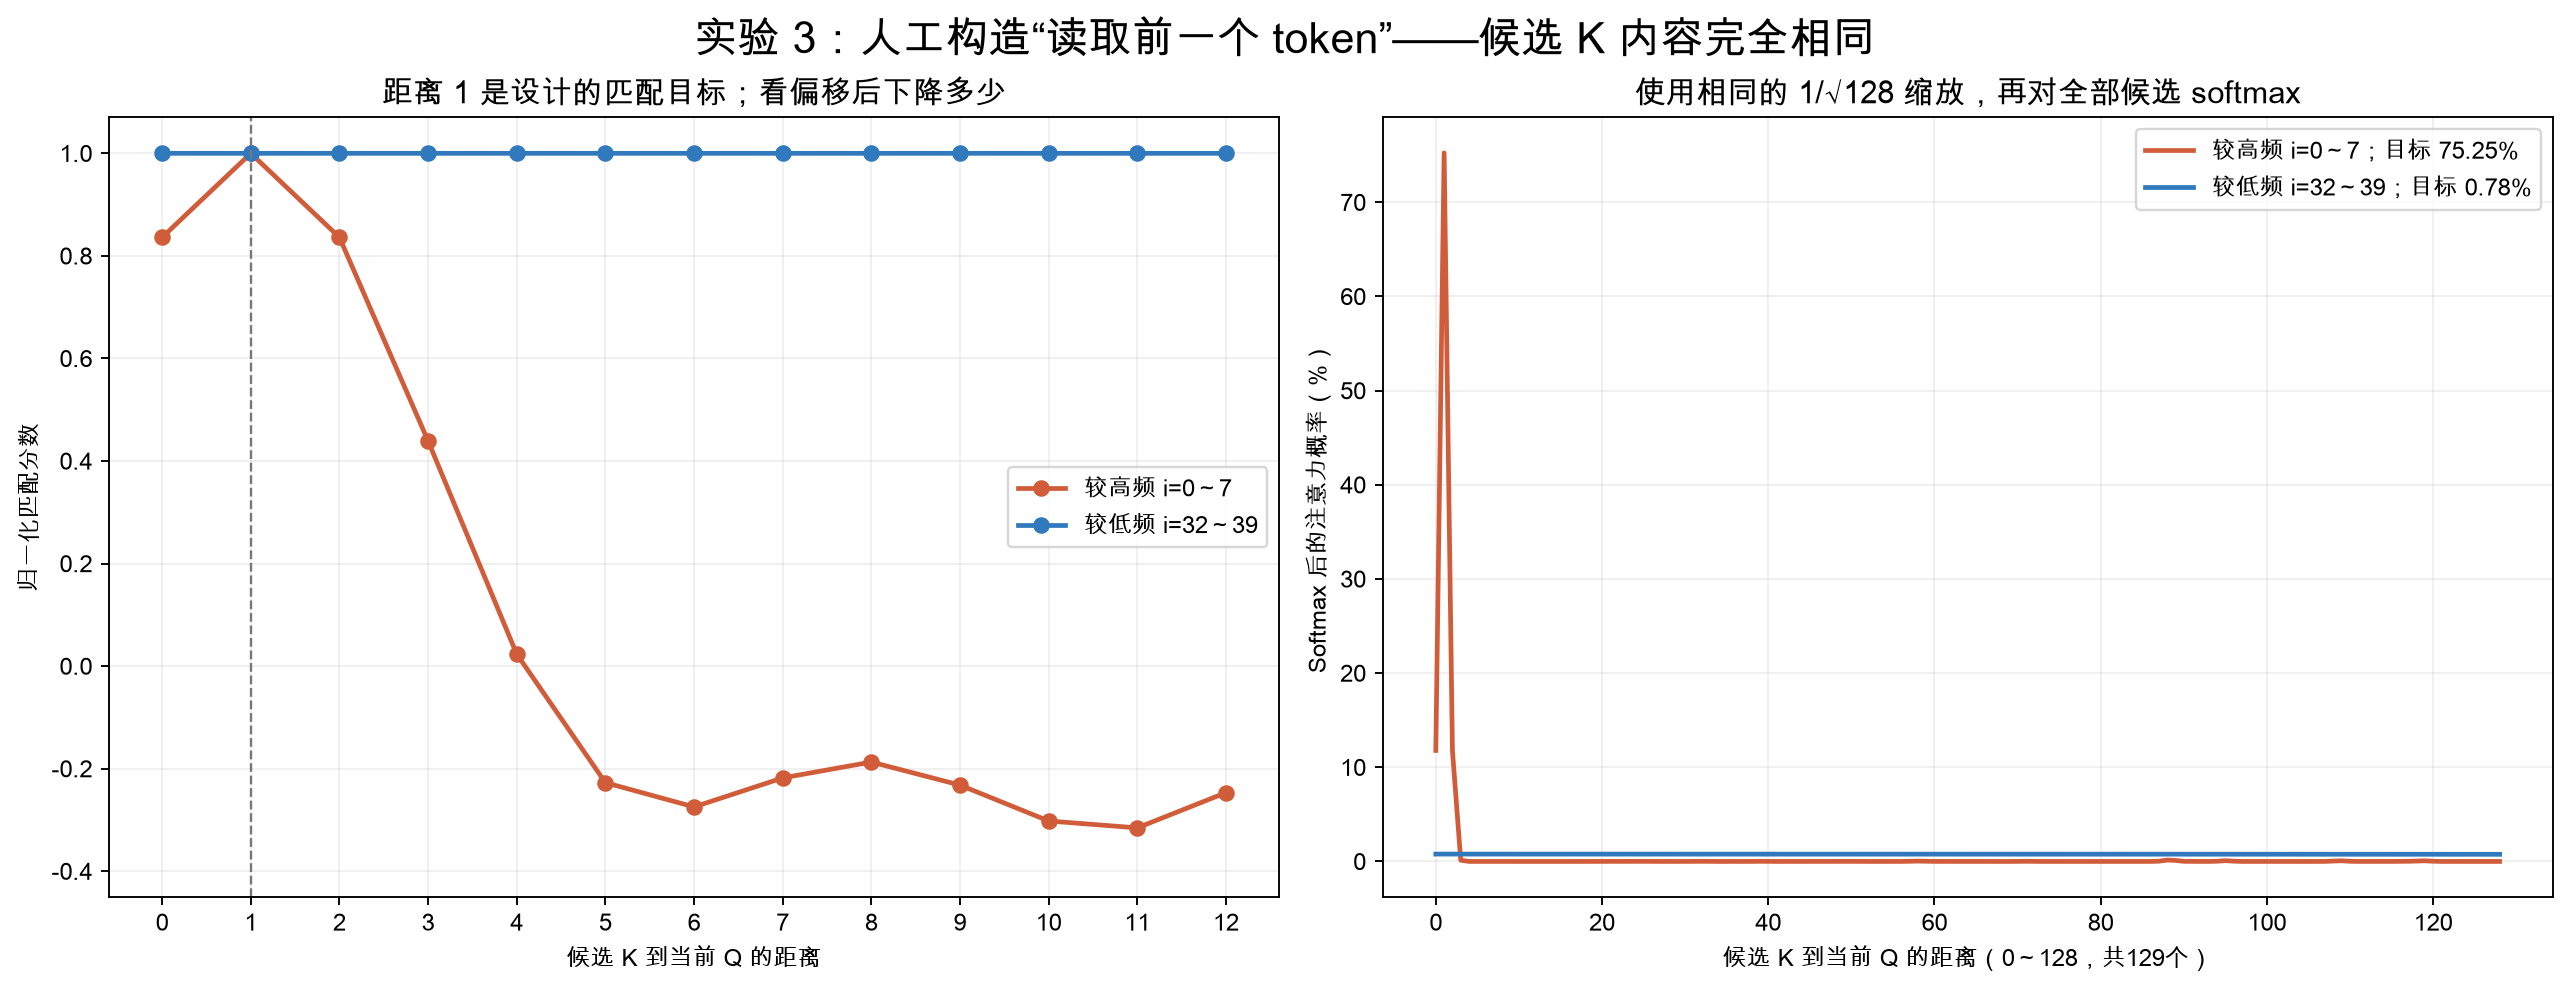

复现命令（仓库根目录）：

```bash
.venv/bin/python 07-modern-llm/rope_frequency_experiment.py
```

完整 64 对频率及相似度在 `assets/rope-experiment/frequency-table.csv`，结果与实验条件在 `results.json`。脚本检查显式旋转矩阵一致性、模长保持、共同平移不变性及单频余弦公式。

## 接下来：让这张结构图真正生成文字

下一课加载真实的小模型权重，沿着“文本 → Token IDs → 网络 → logits → 下一个 token → 解码文本”观察一次推理，再衔接预训练、SFT 和 RL。这一课的运行结果是结构与小矩阵演示，不是实际 Qwen 的生成结果。

图按固定版本资料整理：

- [Qwen3-0.6B 官方配置](https://huggingface.co/Qwen/Qwen3-0.6B/blob/c1899de289a04d12100db370d81485cdf75e47ca/config.json)
- [Transformers v4.51.3 的 Qwen3 实现](https://github.com/huggingface/transformers/blob/v4.51.3/src/transformers/models/qwen3/modeling_qwen3.py)
- 本地来源与校验记录：`assets/source.json`。图片生成代码：`lesson_visuals.py`。

本课不要求猜数字或填写答案；先把每条箭头的输入输出对应清楚。